# Experimento 04 - Análise Temática de Diálogos

In [1]:
#pip install -r requirements.txt2

In [2]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas personas. Considere que a conversa pode ser natural (pode ser como num formato de podcast). Seu trabalho e gerar uma conversa extensa que começa com tópicos relacionados à {topic_1}, mas que gradualmente se move para tópicos relacionados a {topic_2}.

REGRA: Apenas a persona 2 é quem conduz a conversa. Ele introduz a mudança do assunto como um moderador faria, fazendo perguntas ou comentários que levam a conversa para o novo tópico. A persona 1 responde às perguntas e comentários, mas não conduz a conversa.

Além disso, gere uma quantidade significativa de mensagens (pelo menos 100 trocas de mensagens) para garantir uma transição suave e gradual entre os tópicos. É preciso que o moderador faça questionamentos importantes para que a conversa seja rica e interessante.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topic_1}]
Persona 2: [responde, ainda relacionado a {topic_1} ou fazendo uma transição suave]
... 


---------------
"""

prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [4]:
response = chain.invoke({
    "topic_1": "história",
    "topic_2": "matemática"
})

In [5]:
def select_persona(message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversation_list = response.split("\n")
conversation_list = [line for line in conversation_list if line.strip() != ""]
conversation_list_persona = [{"persona": select_persona(line), "message": line[11:]} for line in conversation_list]

In [6]:
system_prompt_summary = """
Você é um assistente inteligente que vai resumir uma conversa entre duas personas. Você vai receber uma lista de mensagens, cada uma associada a uma persona (Persona 1 ou Persona 2). Seu trabalho é gerar um resumo conciso da conversa, dê enfase para o tópico principal discutido na conversa no momento atual (mesmo que o tópico tenha mudado ao longo da conversa). Os tópicos devem girar em torno de {topic_1} e {topic_2}.
"""

prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [7]:
summary_list = []
buffer = []
for i in tqdm(range(len(conversation_list))):
    buffer.append(conversation_list[i])
    buffer_trimmed = buffer[-10:]  
    buffer_str = "\n".join(buffer_trimmed)
    response_summary = chain_summary.invoke({
        "topic_1": "história",
        "topic_2": "matemática",
        "conversation": buffer_str
    })
    summary_list.append(response_summary)

100%|██████████| 29/29 [00:57<00:00,  1.98s/it]


In [8]:
all_data_list = []
for i in range(len(conversation_list)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_list_persona[i]["persona"],
        "message": conversation_list_persona[i]["message"]
    })

os.makedirs("../data/conversation", exist_ok=True)

with open("../data/conversation/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

with open("../data/conversation/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'A conversa aborda a Idade Média, com Persona 1 destacando que esse período não foi tão "escuro" como é frequentemente retratado, ressaltando que avanços culturais e tecnológicos ocorreram, embora tenham sido ofuscados por narrativas posteriores.', 'persona': 'Persona 1', 'message': 'Ah, você sabia que a Idade Média nem sempre foi tão "escura" quanto muita gente imagina? Parece que muitos avanços culturais e tecnológicos aconteceram naquela época, mas acabaram ofuscados por narrativas posteriores.'}, {'summary': 'A conversa aborda a revisão da percepção sobre a Idade Média, desmistificando a ideia de "Idade das Trevas". Os participantes destacam avanços culturais e tecnológicos, como o surgimento das universidades e o desenvolvimento da arquitetura gótica, refletindo sobre aspectos subestimados desse período histórico.', 'persona': 'Persona 2', 'message': 'É verdade, a ideia de "Idade das Trevas" é meio injusta, né? Por exemplo, as universidades surgiram nessa época, sem f

In [10]:
file_path_matematica = "pdfs4/MatematicaI.pdf"
file_path_historia   = "pdfs4/HistoriaI.pdf"

loader_historia   = PyPDFLoader(file_path_historia)
loader_matematica = PyPDFLoader(file_path_matematica)

pages_historia   = loader_historia.load()
pages_matematica = loader_matematica.load()

n_pages = 30
selected_historia   = pages_historia[:n_pages]
selected_matematica = pages_matematica[:n_pages]


In [12]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)


In [14]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

chunks_historia = text_splitter.split_documents(selected_historia)
chunks_matematica = text_splitter.split_documents(selected_matematica)
len(chunks_historia), len(chunks_matematica)

(58, 32)

In [15]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
len(chunks_conversation)

29

In [16]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))
vectors_matematica = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_matematica]))
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_matematica], axis=0)
vectors_conversation.shape, vectors_matematica.shape, vectors_historia.shape, all_vectors.shape

((29, 1536), (32, 1536), (58, 1536), (119, 1536))

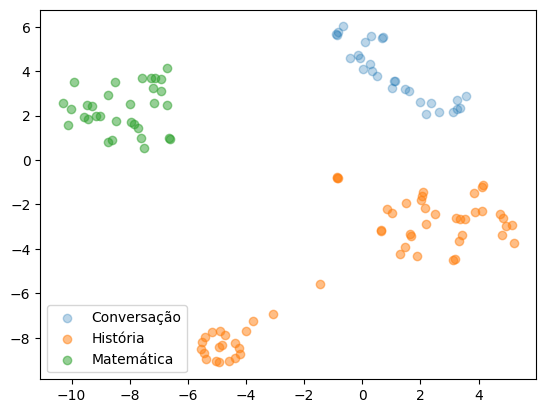

In [17]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="História", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Matemática", alpha=0.5)
plt.legend()
plt.show()

In [18]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_matematica = np.mean(vectors_matematica, axis=0)

In [19]:
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_matematica = cosine_similarity(vectors_conversation, centroid_matematica.reshape(1, -1))
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_matematica": similarity_to_matematica[i, 0]
    })
df = pd.DataFrame(content_and_similarities)
df.sort_values(by="similarity_to_matematica", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
20,A conversa explora como a matemática se manife...,0.348115,0.502915
19,A conversa gira em torno da interseção entre m...,0.387295,0.502438
18,A conversa gira em torno de conceitos matemáti...,0.324704,0.497800
24,A conversa explora a interseção entre matemáti...,0.304045,0.486350
25,A conversa começou com a admiração pela fórmul...,0.319183,0.484905
21,A conversa gira em torno da interconexão entre...,0.360672,0.483379
22,A conversa abordou principalmente a relação en...,0.327813,0.479037
17,A conversa gira em torno da influência da mate...,0.371310,0.464553
16,A conversa explora a relação entre matemática ...,0.376705,0.464138
23,A conversa explorou inicialmente a beleza mate...,0.340225,0.460663


In [20]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
6,"A conversa discute como a Idade Média, apesar ...",0.574410,0.258699
5,A conversa gira em torno da reavaliação da Ida...,0.565724,0.299172
8,A conversa explora avanços culturais e científ...,0.540227,0.298381
7,A conversa gira em torno de desconstruir a ide...,0.528375,0.304725
9,A conversa gira em torno da redescoberta e dos...,0.518045,0.365781
4,A conversa focou na desconstrução do conceito ...,0.516034,0.276010
3,A conversa gira em torno da reavaliação da Ida...,0.510560,0.297225
10,A conversa foca na relevância de avanços cultu...,0.504196,0.381153
13,A conversa começou abordando a influência cult...,0.492880,0.380095
12,A conversa explorou inicialmente o papel da Ig...,0.486613,0.382657


In [21]:
example_matematica = df.sort_values(by="similarity_to_matematica", ascending=False).head(10)['chunk'].values
for x in example_matematica:
    print(x)

A conversa explora como a matemática se manifesta tanto na natureza quanto na arte e na prática humana. Inicialmente, os participantes discutem a sequência de Fibonacci e sua conexão com a razão áurea, abordando seu apelo visual e impacto estético na arte e na arquitetura. O diálogo então avança para o fascínio por equações e conceitos matemáticos, destacando a elegância da fórmula de Euler e sua conexão com diferentes áreas da matemática. Por fim, eles refletem sobre a aplicação prática da matemática, desde os circuitos elétricos até a geometria utilizada na construção de catedrais medievais, destacando o papel essencial da matemática em moldar o mundo natural e cultural.
A conversa gira em torno da interseção entre matemática e fenômenos naturais, culturais e históricos. Após discutirem a sequência de Fibonacci e sua relação com a razão áurea na natureza, arte e arquitetura, as personas exploram o impacto da matemática como um todo na compreensão do mundo, destacando a fórmula de Eul

In [22]:
example_historia = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_historia:
    print(x)

A conversa discute como a Idade Média, apesar de frequentemente vista como um período de estagnação, foi repleta de avanços culturais, científicos e tecnológicos. Os participantes destacam a preservação e propagação do conhecimento por mosteiros, a influência da Igreja, e o intercâmbio cultural na Península Ibérica que levou a inovações em medicina e astronomia. O tópico principal finaliza com o papel do astrolábio, um instrumento desenvolvido nesse período, e sua importância prática para a navegação e as grandes expedições marítimas.
A conversa gira em torno da reavaliação da Idade Média e seus avanços frequentemente subestimados. Os participantes discutem contribuições culturais e tecnológicas, como o papel dos mosteiros na preservação de manuscritos antigos, o surgimento das universidades e avanços arquitetônicos como as catedrais góticas. Também mencionam a interação cultural na Península Ibérica, que impulsionou áreas como medicina e astronomia, além do impacto de instrumentos com

In [23]:
vectors_conversation

array([[-0.00270621,  0.01664625,  0.01133831, ...,  0.0045616 ,
         0.0213392 ,  0.0312147 ],
       [ 0.01564481,  0.0421652 ,  0.02819185, ..., -0.00313119,
         0.01360563,  0.00738783],
       [ 0.01642132,  0.043155  ,  0.03721418, ..., -0.00614258,
         0.00966224,  0.01193768],
       ...,
       [-0.01642994, -0.00677951,  0.02824797, ..., -0.01316701,
         0.01556521,  0.03232951],
       [ 0.01830968,  0.01111735,  0.03458259, ..., -0.02552322,
        -0.001149  ,  0.01970995],
       [ 0.02021044, -0.00349298,  0.04329101, ..., -0.02975759,
        -0.00144254,  0.01046399]], shape=(29, 1536))

In [24]:
sims_delta_s = []
cosine_similarities = []
for i in range(1, len(vectors_conversation)):
    delta = vectors_conversation[i] - vectors_conversation[i-1]
    delta_cos_sim = cosine_similarity(vectors_conversation[i].reshape(1, -1), vectors_conversation[i-1].reshape(1, -1))[0,0]
    sims_delta_s.append(delta)
    cosine_similarities.append(delta_cos_sim)
sims_delta_s = np.array(sims_delta_s)
cosine_similarities = np.array(cosine_similarities)

In [25]:
sims_delta_s.shape, cosine_similarities.shape

((28, 1536), (28,))

In [26]:
mods = np.linalg.norm(sims_delta_s, axis=1)
idxs_persona_1 = list(range(1, len(mods), 2))
idxs_persona_2 = list(range(0, len(mods), 2))

mods_persona_1 = mods[idxs_persona_1]
mods_persona_2 = mods[idxs_persona_2]

mods_cos_similarities_persona_1 = cosine_similarities[idxs_persona_1]
mods_cos_similarities_persona_2 = cosine_similarities[idxs_persona_2]

In [27]:
mods_persona_1.mean(), mods_persona_2.mean()

(np.float64(0.48071675532730973), np.float64(0.5506707539953881))

In [28]:
mods_cos_similarities_persona_1.mean(), mods_cos_similarities_persona_2.mean()

(np.float64(0.8786136909232786), np.float64(0.8420501751100155))

In [29]:
mods_cos_similarities_persona_1.std(), mods_cos_similarities_persona_2.std()

(np.float64(0.0556779907717362), np.float64(0.061891563275339644))